In [34]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from scipy.optimize import linprog

# Introduction: Data Analysis, Visualization, and Modeling
To get your feet wet, we will start with the `80-cerals` dataset to start learning the basics of `pandas`, how to handle missin g values, and basic data visualization. The dataset contains $16$ columns: `name`, `mfr`, `type`, `calories`, `protein`, `fat`, `sodium`, `fiber`, `carbo`, `sugars`, `potass`, `vitamins`, `shelf`, `weight`, `cups`, and `rating`. More information from the Kaggle page is below:

```
Fields in the dataset:

Name: Name of cereal
mfr: Manufacturer of cereal
  A = American Home Food Products;
  G = General Mills
  K = Kelloggs
  N = Nabisco
  P = Post
  Q = Quaker Oats
  R = Ralston Purina

type:
  cold
  hot

calories: calories per serving

protein: grams of protein

fat: grams of fat

sodium: milligrams of sodium

fiber: grams of dietary fiber

carbo: grams of complex carbohydrates

sugars: grams of sugars

potass: milligrams of potassium

vitamins: vitamins and minerals - 0, 25, or 100, indicating the typical percentage of FDA recommended

shelf: display shelf (1, 2, or 3, counting from the floor)

weight: weight in ounces of one serving

cups: number of cups in one serving

rating: a rating of the cereals (Possibly from Consumer Reports?)
```

To get started let's first load in the dataset.

In [2]:
# download ceral dataset sales dataset from Kaggle
import kagglehub
path = kagglehub.dataset_download("crawford/80-cereals")
df = pd.read_csv(path + "/cereal.csv")

# Replace -1 with NaN in the specific columns
columns_to_clean = ['carbo', 'sugars', 'potass']

df[columns_to_clean] = df[columns_to_clean].replace(-1, np.nan)

df.head()

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.0,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.0,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.0,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.0,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8.0,NaN,25,3,1.0,0.75,34.384843


To get a better sense of the actual size of our data, let's print out its shape using the built-in Pandas `.shape` method.

In [3]:
df.shape # returns (# of rows, # of columns)

(77, 16)

Great! So we can see that our dataset has $77$ rows and $16$ columns.

Now before we continue it's important for us to make a note that often times in real-world data there will be "missing values" which can occur for a variety of reasons (e.g. someone didn't fill out a certain section in a survey, a sensor failed, etc.) which can pose a problem when we want to use the data to build a model. Often times a missing value may be denoted with `NaN` (Not a Number) or some other value to denote that a value could not be recorded. Let's look to see how many values are missing from our dataset:

In [4]:
df[df.isna().any(axis=1)].shape[0]

3

So it turns out that $3$ out of our $77$ rows have a missing value somewhere. So what do we do about these pesky missing values? One option that might come to mind is to simply "throw out" the rows in our dataset that contain a `NaN` value and use the rest, so in our case we would throw out the $3$ rows and be left with a dataset with $74$ rows instead.

In [5]:
len(df.dropna())

74

In this particular case that might not be too concerning, after all what's $3$ data points, but what happens if more of your dataset has missing values? You would end up an extremely small dataset and might have no chance of building a sensible model! So another approach is known as *data imputation* where we try to fill in missing values with a sensible replacement value (e.g. mean, median, mode, etc.), for our case let's replace the missing values with the *mean* of their respective columns.

In [6]:
# Fill NaN values in numeric columns with their respective column mean
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

# Verify that there are no more missing values left
remaining_na = df.isna().sum().sum()
print(f"Remaining missing values in df: {remaining_na}")
display(df.head())
print(df.shape)

Remaining missing values in df: 0


,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6.0,280.000000,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8.0,135.000000,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5.0,320.000000,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0.0,330.000000,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8.0,98.666667,25,3,1.0,0.75,34.384843


(77, 16)


Now we have preserved all $77$ rows of our dataset! Next let's take a look at actually visualizing our dataset by plotting histograms of our numerical columns of our dataset.

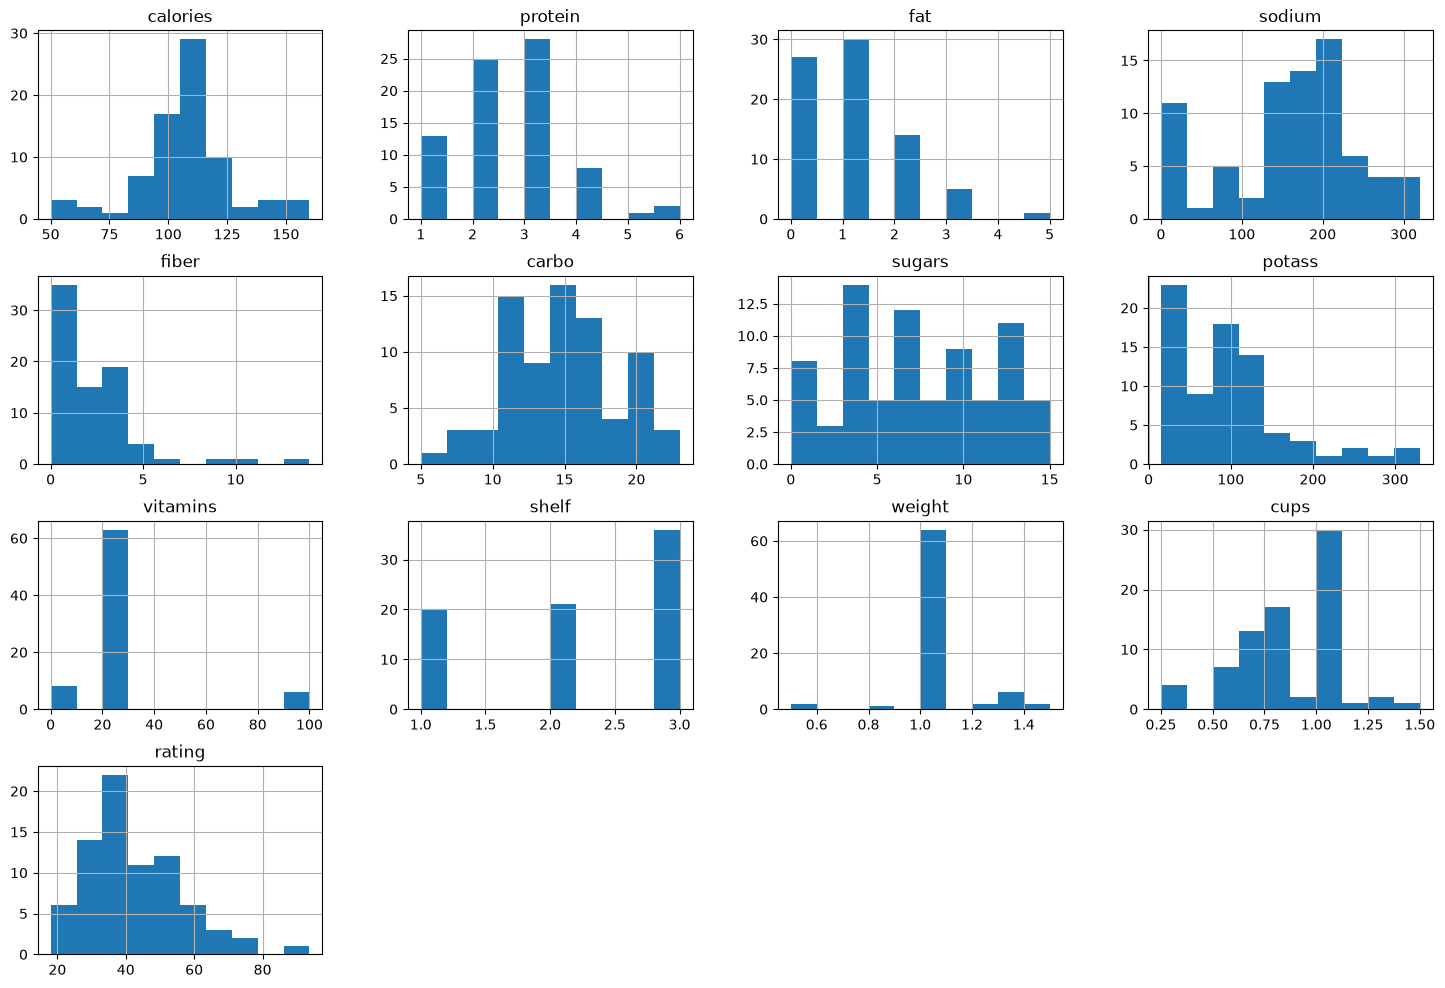

In [7]:
df.hist(figsize=(18, 12))
plt.show()

We trying to determine relationships within "features" of our data we can start by looking at a correlation matrix, so let's do that below:

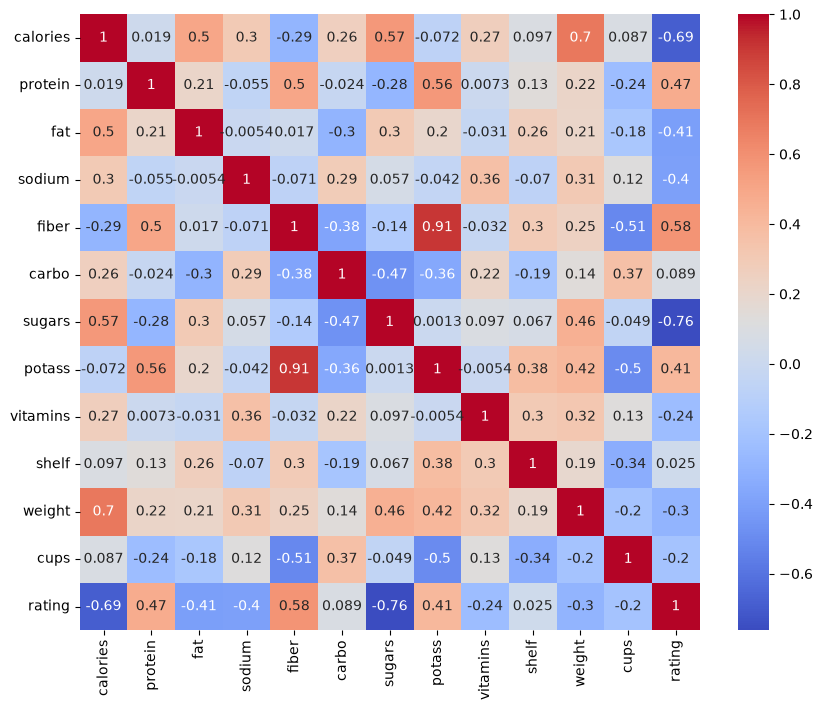

In [8]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

It seems for example that `sugar` and `rating` are highly correlated, so let's look at `sugars vs rating`:

<Axes: xlabel='sugars', ylabel='rating'>

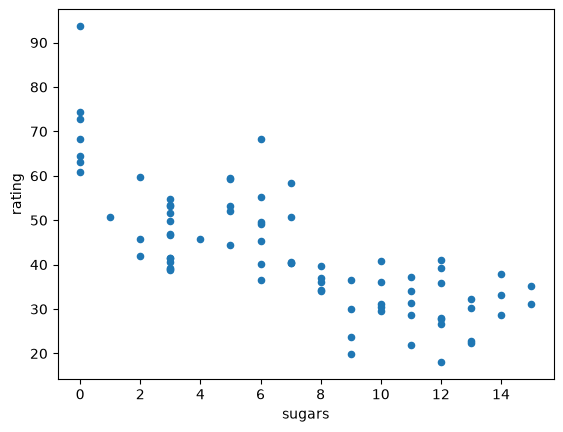

In [9]:
df.plot(kind="scatter", x="sugars", y="rating")

Now suppose, we wanted to fit a line to the sugar vs ratings relationship above. One such way is to use **Linear Regression** which aims to find the coefficients of line that minimizes the distance to all of our data points. More formally, Linear Regression is to find $\beta_0, \beta$ such that
$$
  (\beta, \beta_0) = \arg \min \frac{1}{N}\sum_{i=1}^N (\beta_0 + \beta x_i - y_i)^2
$$
the distance metric above is known as the **Mean Square Error (MSE)**. Let's use `scikit-learn` library to create a linear model using Linear Regression.


In [10]:
X = df[["sugars"]]
y = df["rating"]
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-2.46]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['sugars']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,59.96
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [11]:
print(f"Model intercept: {model.intercept_}")
print(f"Model coefficient: {model.coef_}")

Model intercept: 59.960420687104886
Model coefficient: [-2.46142021]


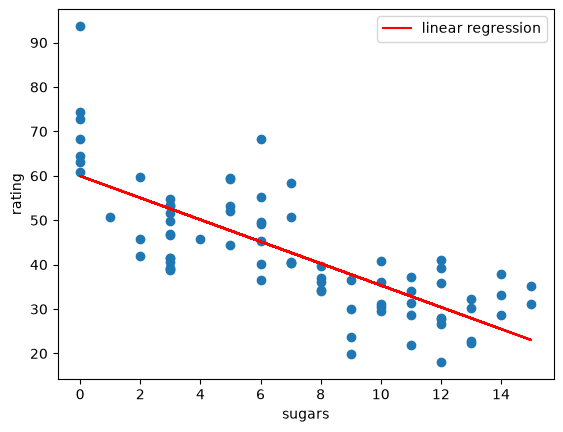

In [12]:
plt.scatter(X, y)
plt.plot(X, model.predict(X), color="red", label="linear regression")
plt.legend()
plt.xlabel("sugars")
plt.ylabel("rating")
plt.show()

In [13]:
# Compute 1D linear regression model MSE
err = mean_squared_error(y, model.predict(X))
print(f"Mean squared error: {err}")

Mean squared error: 81.62165752457801


Another metric useful for Linear Regression models is the $R^2$-score, which tells us how well our model explains the variance of $y$ with respect to $x$, and can be computed as

$$
  R^2 = 1 - \frac{\sum_{i=1}^N (y_i - \hat{y}_i)^2}{\sum_{i=1}^N (y_i - \bar{y})^2}
$$

In [14]:
# Compute 1D Linear Regression R^2 Score
r_score = model.score(X, y)
print(f"R-squared score: {r_score}")

R-squared score: 0.5809194320222827


Of course we can also use linear regression in higher-dimensions as well, so let's say we wanted to also include `fat` alongside `sugar` for predicting our `rating`

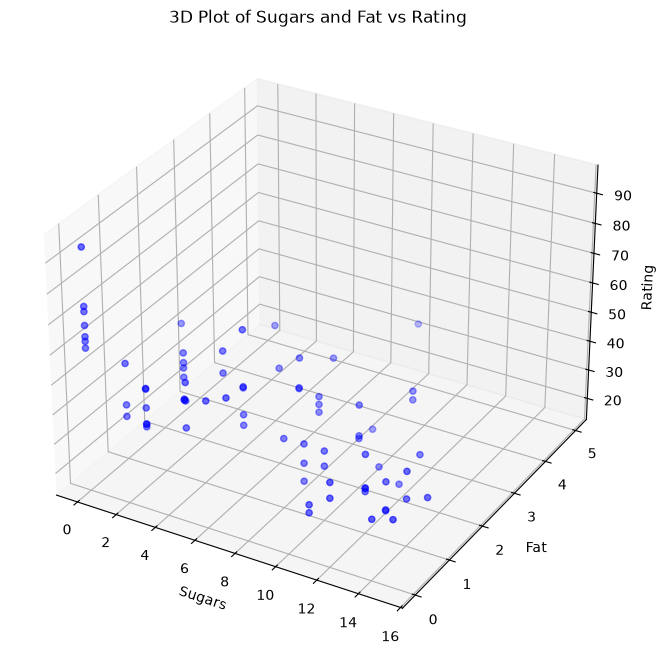

In [15]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df['sugars'], df['fat'], df['rating'], c='blue', marker='o', alpha=0.8)

# Set labels
ax.set_xlabel('Sugars')
ax.set_ylabel('Fat')
ax.set_zlabel('Rating')
ax.set_title('3D Plot of Sugars and Fat vs Rating')

plt.show()

In [16]:
# Define multiple features
X_multi = df[['sugars', 'fat']]
y_multi = df['rating']

# Fit the linear regression model
multi_model = LinearRegression()
multi_model.fit(X_multi, y_multi)

# Output model parameters and MSE
print(f"Model intercept: {multi_model.intercept_}")
print(f"Model coefficients (sugars, fat): {multi_model.coef_}")

multi_err = mean_squared_error(y_multi, multi_model.predict(X_multi))
print(f"Mean squared error with sugars and fat: {multi_err}")

Model intercept: 61.41021340309015
Model coefficients (sugars, fat): [-2.26913757 -2.76492318]
Mean squared error with sugars and fat: 74.66859701511162


/Users/nreef/Desktop/siam_python_data_workshop/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


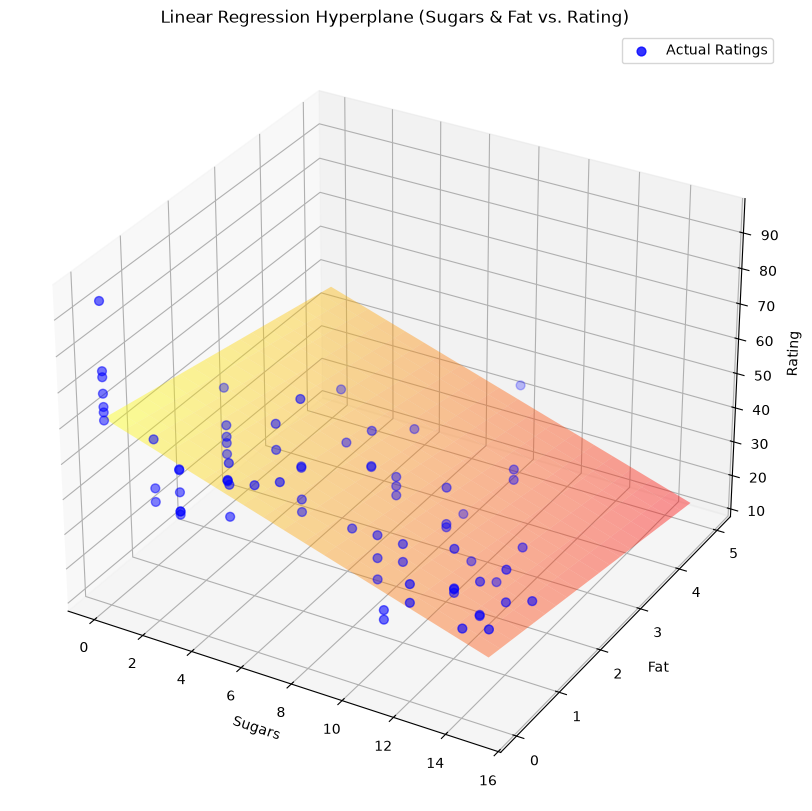

In [17]:
# Create a coordinate grid over sugars and fat
x_range = np.linspace(df['sugars'].min(), df['sugars'].max(), 20)
y_range = np.linspace(df['fat'].min(), df['fat'].max(), 20)
X_grid, Y_grid = np.meshgrid(x_range, y_range)

# Flatten the grid to run predictions, then reshape back to a 2D grid
grid_features = np.c_[X_grid.ravel(), Y_grid.ravel()]
Z_grid = multi_model.predict(grid_features).reshape(X_grid.shape)

# Initialize the 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the actual data points as a scatter plot
ax.scatter(df['sugars'], df['fat'], df['rating'], c='blue', marker='o', s=40, label='Actual Ratings', alpha=0.8)

# Plot the regression hyperplane
surface = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='autumn', alpha=0.4, rstride=1, cstride=1, edgecolor='none')

# Set labels and title
ax.set_xlabel('Sugars')
ax.set_ylabel('Fat')
ax.set_zlabel('Rating')
ax.set_title('Linear Regression Hyperplane (Sugars & Fat vs. Rating)')
ax.legend()

plt.show()

In [18]:
# Compute 2D Linear Regression Model MSE
err = mean_squared_error(y_multi, multi_model.predict(X_multi))
print(f"Mean squared error: {err}")

Mean squared error: 74.66859701511162


In [19]:
# Compute 2D Linear Regression Model R^2 Score
r_score = multi_model.score(X_multi, y_multi)
print(f"R-squared score: {r_score}")

R-squared score: 0.6166194243510734


Which seems to be an improvement on our $1$ D case! Note that we are also not limited to linear models, another approach is Polynomial Regression where we want to learn the coefficients of a polynomial that minimizes the MSE.

In [20]:
X = df[["sugars"]]
y = df["rating"]

In [21]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['sugars']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",4
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


/Users/nreef/Desktop/siam_python_data_workshop/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


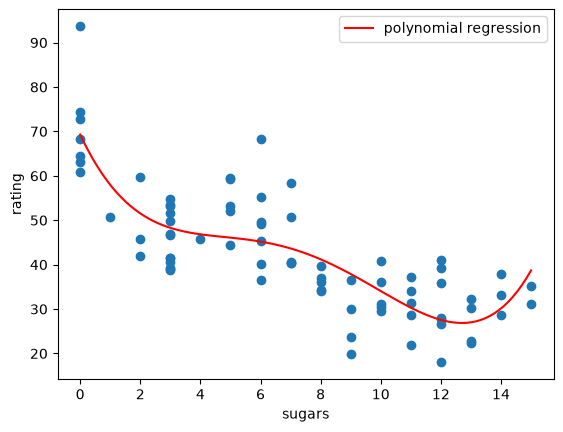

In [22]:
plt.scatter(X, y)
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(X_range, model.predict(X_range), color="red", label="polynomial regression")
plt.legend()
plt.xlabel("sugars")
plt.ylabel("rating")
plt.show()

In [23]:
# Compute Polynomial Regression Model MSE
err = mean_squared_error(y, model.predict(X))
print(f"Mean squared error: {err}")

Mean squared error: 61.15063708829428


In [24]:
# Compute Polymial Regression Model R^2-Score
print(f"R-squared score: {model.score(X, y)}")

R-squared score: 0.6860264236186973


## Model selection & Overfitting
So it seems our degree $2$ polynomial has a much smaller MSE than our linear model, so does this mean that it is inherently better? The answer is no! If you continually increase the degree of the polynomial you are fitting, you will find that it will eventually pass through all the points in our dataset and achieve a perfect MSE of $0$. This on paper might seem good but you can imagine that if our data has noise then fitting exactly is not what we want since we would only learn the noise and not the actual relationship of interest. Additionally the model will be heavily biased to the distribution of the sample data, and thus won't generalize well to new data points outside our sample.  

One way to get around this is to first split our dataset into a **training** and **testing** sets, that way we can have data points that our model did not see when we made it and see if it also able to describe these data points as well. 

In [25]:
# Correct the train/test split unpacking order
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for degree in range(1, 10):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Degree {degree} -> MSE: {mse:.4f}, R2: {r2:.4f}")

Degree 1 -> MSE: 97.5263, R2: 0.4031
Degree 2 -> MSE: 91.5264, R2: 0.4398
Degree 3 -> MSE: 99.4780, R2: 0.3912
Degree 4 -> MSE: 105.6413, R2: 0.3535
Degree 5 -> MSE: 151.1685, R2: 0.0748
Degree 6 -> MSE: 143.7844, R2: 0.1200
Degree 7 -> MSE: 115.7774, R2: 0.2914
Degree 8 -> MSE: 137.8763, R2: 0.1562
Degree 9 -> MSE: 253.7338, R2: -0.5529


## Linear Programming & Optimization
Suppose we want to mix cereals to maximize fiber while keeping sugar between 10 and 20 g and calories at or below 100 kcal. Let \(x_i\) be the fraction of one dataset serving contributed by cereal \(i\). The per-serving fiber, sugar, and calorie values are \(f_i\), \(s_i\), and \(c_i\). We require the fractions to sum to one so the bowl size is fixed:

$$
\begin{aligned}
\text{maximize}_{x} \quad & \sum_i f_i x_i \\ 
\text{subject to} \quad & 10 \leq \sum_i s_i x_i \leq 20, \\ 
& \sum_i c_i x_i \leq 100, \\ 
& \sum_i x_i = 1, \qquad x_i \geq 0.
\end{aligned}
$$
The nutrient values are treated as proportional to the fraction of a serving. We use the cleaned data from above, including its imputed missing values. A mix is allowed, but the optimum may use just one cereal.

In [26]:
cereals = df[['name', 'fiber', 'sugars', 'calories']].dropna().reset_index(drop=True)
fiber = cereals['fiber'].to_numpy()
sugar = cereals['sugars'].to_numpy()
calories = cereals['calories'].to_numpy()

# linprog minimizes, so negate fiber to maximize it.
sugar_min, sugar_max, calorie_max = 10, 20, 100
solution = linprog(
    c=-fiber,
    A_ub=np.vstack([sugar, -sugar, calories]),
    b_ub=[sugar_max, -sugar_min, calorie_max],
    A_eq=np.ones((1, len(cereals))),
    b_eq=[1],
    bounds=(0, None),
    method='highs',
)
if not solution.success:
    raise RuntimeError(f'No optimal bowl found: {solution.message}')

mix = cereals.loc[solution.x > 1e-8, ['name']].copy()
mix['fraction_of_serving'] = solution.x[solution.x > 1e-8]
print(mix.to_string(index=False))
print(f'Fiber: {fiber @ solution.x:.2f} g')
print(f'Sugar: {sugar @ solution.x:.2f} g (range: {sugar_min}–{sugar_max} g)')
print(f'Calories: {calories @ solution.x:.2f} kcal (limit: {calorie_max} kcal)')

                     name  fraction_of_serving
All-Bran with Extra Fiber             0.285714
    Post Nat. Raisin Bran             0.714286
Fiber: 8.29 g
Sugar: 10.00 g (range: 10–20 g)
Calories: 100.00 kcal (limit: 100 kcal)


## Classification with the Iris dataset
Regression predicts a number, such as cereal rating. **Classification** predicts a category. The built-in Iris dataset contains four flower measurements and one of three species labels. We will use the same stratified train/test split to compare two classifiers.

In [32]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris, y_iris, test_size=0.3, stratify=y_iris, random_state=42
)
print(f'Species: {", ".join(iris.target_names)}')
print(f'Training flowers: {len(X_iris_train)}; test flowers: {len(X_iris_test)}')
display(X_iris.head())

Species: setosa, versicolor, virginica
Training flowers: 105; test flowers: 45


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### K-nearest neighbors (KNN)
KNN predicts a flower's species by voting among its nearest training examples. Distances depend on feature scale, so the pipeline standardizes measurements using only the training data before fitting a 5-neighbor classifier.

In [33]:
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_model.fit(X_iris_train, y_iris_train)
knn_accuracy = accuracy_score(y_iris_test, knn_model.predict(X_iris_test))
print(f'KNN test accuracy: {knn_accuracy:.1%}')

KNN test accuracy: 91.1%


### Decision tree
A decision tree learns a sequence of threshold rules, such as whether a petal measurement is below a certain value. We limit its depth to keep the rules readable and reduce overfitting. The test accuracies below come from one split; for tuning either model, use cross-validation on the training set.

KNN test accuracy:          91.1%
Decision tree test accuracy: 97.8%


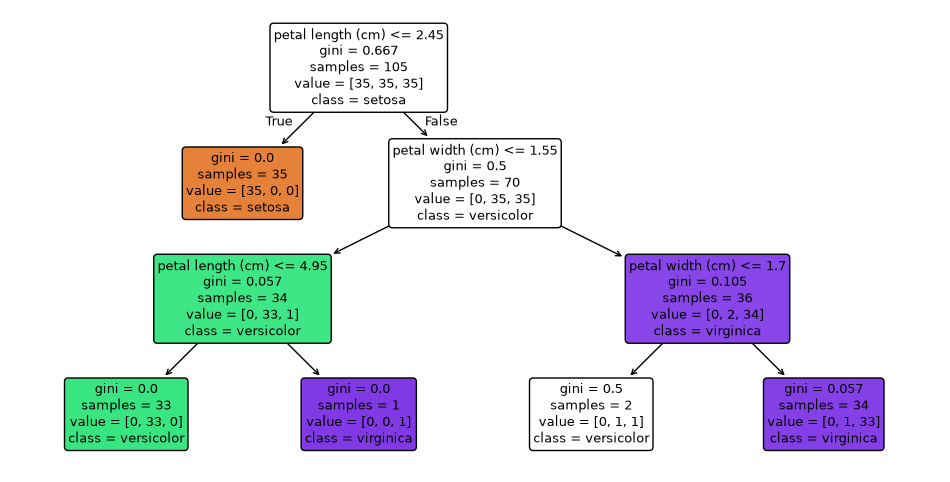

In [35]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_iris_train, y_iris_train)
tree_accuracy = accuracy_score(y_iris_test, tree_model.predict(X_iris_test))
print(f'KNN test accuracy:          {knn_accuracy:.1%}')
print(f'Decision tree test accuracy: {tree_accuracy:.1%}')

plt.figure(figsize=(12, 6))
plot_tree(
    tree_model, feature_names=iris.feature_names,
    class_names=list(iris.target_names), filled=True, rounded=True, fontsize=9
)
plt.show()

### Visualizing the Iris measurements
Each point is one flower, colored by its true species. The petal measurements separate the species more clearly than the sepal measurements in these two-dimensional views.

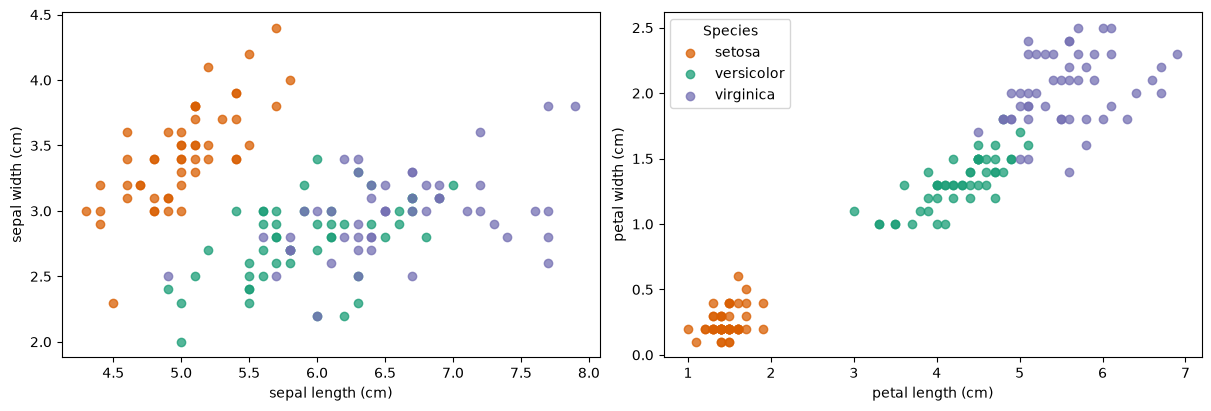

In [30]:
feature_pairs = [
    ('sepal length (cm)', 'sepal width (cm)'),
    ('petal length (cm)', 'petal width (cm)'),
]
species_colors = ['#d95f02', '#1b9e77', '#7570b3']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (x_name, y_name) in zip(axes, feature_pairs):
    for species_id, (species_name, color) in enumerate(zip(iris.target_names, species_colors)):
        points = y_iris == species_id
        ax.scatter(X_iris.loc[points, x_name], X_iris.loc[points, y_name],
                   label=species_name, color=color, alpha=0.75)
    ax.set(xlabel=x_name, ylabel=y_name)
axes[1].legend(title='Species')
plt.show()

### Model decision regions over the flowers
A decision region shows which species a model predicts at each pair of petal measurements. To draw these two-dimensional regions, we fit new KNN and decision-tree models using **only petal length and width**. The test accuracies above belong to the earlier four-feature models.

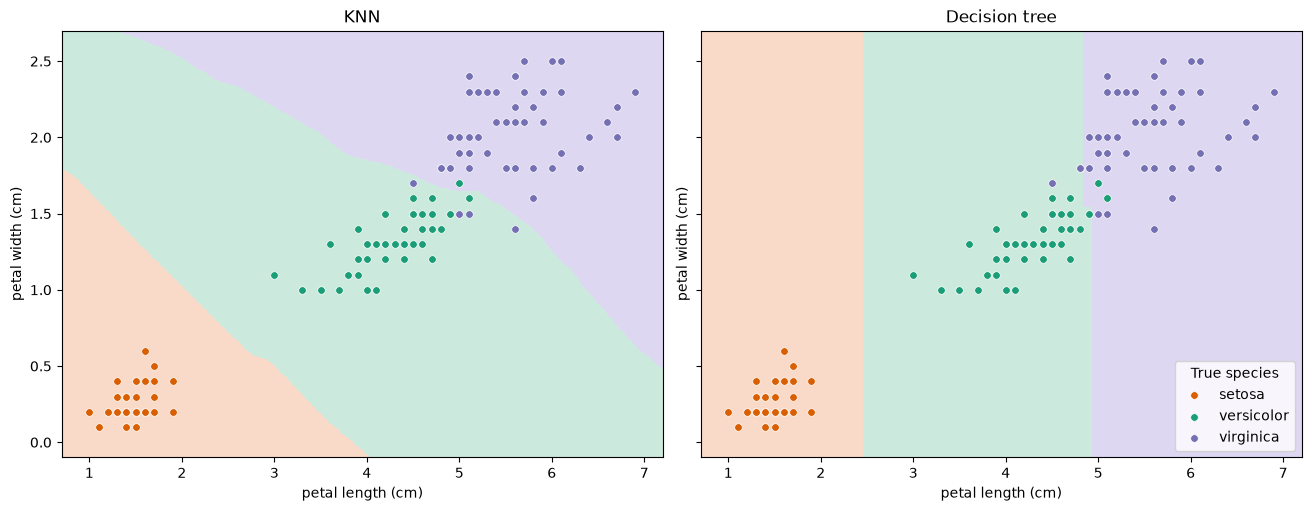

In [31]:
import numpy as np
import pandas as pd

petal_features = ['petal length (cm)', 'petal width (cm)']
X_petal_train = X_iris_train[petal_features]
knn_petal = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
tree_petal = DecisionTreeClassifier(max_depth=3, random_state=42)
knn_petal.fit(X_petal_train, y_iris_train)
tree_petal.fit(X_petal_train, y_iris_train)

x_values = np.linspace(X_iris[petal_features[0]].min() - 0.3,
                       X_iris[petal_features[0]].max() + 0.3, 250)
y_values = np.linspace(X_iris[petal_features[1]].min() - 0.2,
                       X_iris[petal_features[1]].max() + 0.2, 250)
grid_x, grid_y = np.meshgrid(x_values, y_values)
grid = pd.DataFrame({petal_features[0]: grid_x.ravel(),
                     petal_features[1]: grid_y.ravel()})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True,
                         constrained_layout=True)
region_colors = ['#f9d9c8', '#cce9dd', '#ddd7f1']
for ax, (title, fitted_model) in zip(axes, [('KNN', knn_petal),
                                            ('Decision tree', tree_petal)]):
    predicted_regions = fitted_model.predict(grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, predicted_regions,
                levels=[-0.5, 0.5, 1.5, 2.5], colors=region_colors)
    for species_id, (species_name, color) in enumerate(zip(iris.target_names, species_colors)):
        points = y_iris == species_id
        ax.scatter(X_iris.loc[points, petal_features[0]],
                   X_iris.loc[points, petal_features[1]],
                   label=species_name, color=color, edgecolor='white',
                   linewidth=0.5, s=30)
    ax.set(title=title, xlabel=petal_features[0], ylabel=petal_features[1])
axes[1].legend(title='True species', loc='lower right')
plt.show()